<a href="https://colab.research.google.com/github/kartikkk2005/ML_lab_II/blob/main/kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Means Clustering: Customer Income vs Spending Score
A simple customer segmentation example using the **Elbow Method** (WCSS) to choose the number of clusters.

## 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

## 2. Create the dataset (300 data points)
Five customer groups are simulated, each with a different mix of annual income and spending score (1-100).

In [ ]:
np.random.seed(7)

def make_group(n, income_mean, score_mean):
    income = np.random.normal(income_mean, 6, n)
    score = np.random.normal(score_mean, 6, n)
    return np.column_stack([income, score])

data = np.vstack([
    make_group(60, 25, 20),   # low income, low spending
    make_group(60, 25, 80),   # low income, high spending
    make_group(60, 55, 50),   # medium income, medium spending
    make_group(60, 88, 18),   # high income, low spending
    make_group(60, 88, 82),   # high income, high spending
])

df = pd.DataFrame(data, columns=["Annual_Income_k", "Spending_Score"])
df["Annual_Income_k"] = df["Annual_Income_k"].clip(10, 130).round(1)
df["Spending_Score"] = df["Spending_Score"].clip(1, 100).round(0).astype(int)

print("Total data points:", len(df))
df.head(10)

Total data points: 300


,Annual_Income_k,Spending_Score
0,35.1,18
1,22.2,9
2,25.2,19
3,27.4,30
4,20.3,18
5,25.0,15
6,25.0,13
7,14.5,14
8,31.1,18
9,28.6,13


In [ ]:
df.describe()

,Annual_Income_k,Spending_Score
count,300.000000,300.000000
mean,55.639000,49.933333
std,28.726458,28.694019
min,11.300000,1.000000
25%,26.575000,21.000000
50%,54.900000,49.000000
75%,85.425000,79.250000
max,98.700000,97.000000


## 3. Visualise the raw data

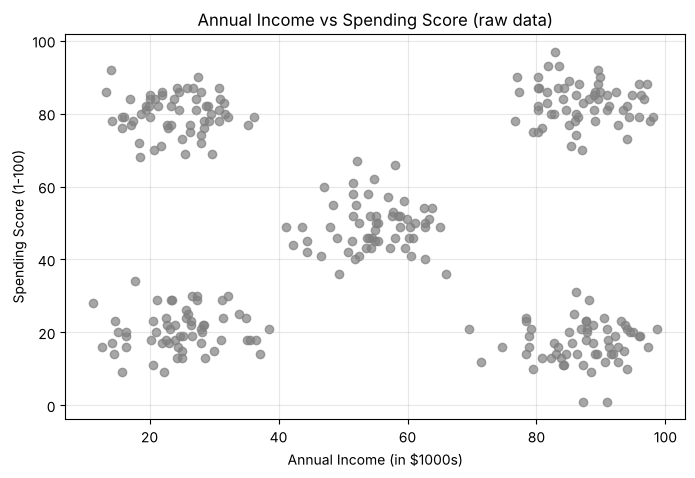

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Annual_Income_k"], df["Spending_Score"], color="gray", alpha=0.7)
plt.title("Annual Income vs Spending Score (raw data)")
plt.xlabel("Annual Income (in $1000s)")
plt.ylabel("Spending Score (1-100)")
plt.grid(alpha=0.3)
plt.show()

## 4. Scale the features
K-Means uses distances, so both features should be on the same scale.

In [ ]:
X = df[["Annual_Income_k", "Spending_Score"]].values
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

## 5. Elbow Method (WCSS)
**WCSS** = Within-Cluster Sum of Squares (`inertia_` in scikit-learn). It measures how tightly points sit around their cluster centre. We run K-Means for K = 1 to 10 and look for the *elbow*, where WCSS stops dropping sharply.

In [ ]:
wcss = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

for k, w in zip(k_range, wcss):
    print(f"K = {k:2d}  ->  WCSS = {w:.2f}")

K =  1  ->  WCSS = 600.00
K =  2  ->  WCSS = 350.06
K =  3  ->  WCSS = 198.72
K =  4  ->  WCSS = 87.38
K =  5  ->  WCSS = 24.82
K =  6  ->  WCSS = 22.64
K =  7  ->  WCSS = 20.61
K =  8  ->  WCSS = 18.60
K =  9  ->  WCSS = 17.15
K = 10  ->  WCSS = 15.38


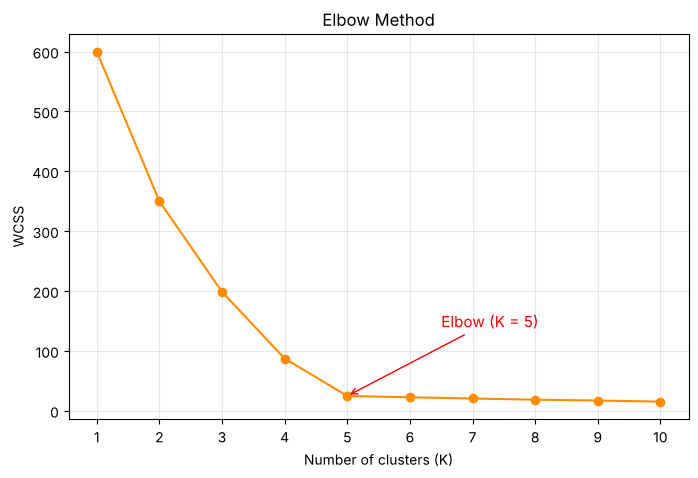

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker="o", color="darkorange")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(k_range)
plt.grid(alpha=0.3)
plt.annotate("Elbow (K = 5)", xy=(5, wcss[4]), xytext=(6.5, wcss[4] + (wcss[0] - wcss[4]) * 0.2),
             arrowprops=dict(arrowstyle="->", color="red"), color="red", fontsize=11)
plt.show()

The curve bends sharply at **K = 5**, so 5 is the best number of clusters.

## 6. Fit K-Means with K = 5

In [ ]:
kmeans = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# Convert centroids back to the original scale for plotting
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
df.head()

,Annual_Income_k,Spending_Score,Cluster
0,35.1,18,2
1,22.2,9,2
2,25.2,19,2
3,27.4,30,2
4,20.3,18,2


## 7. Visualise the clusters

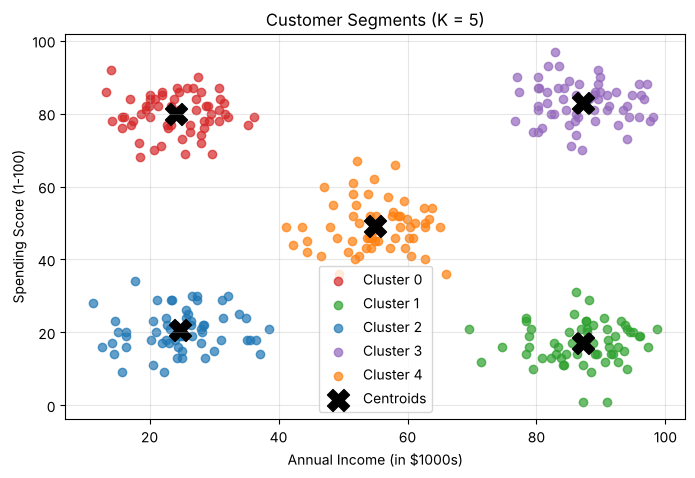

In [ ]:
colors = ["tab:red", "tab:green", "tab:blue", "tab:purple", "tab:orange"]

plt.figure(figsize=(8, 5))
for c in range(5):
    pts = df[df["Cluster"] == c]
    plt.scatter(pts["Annual_Income_k"], pts["Spending_Score"], color=colors[c], alpha=0.7, label=f"Cluster {c}")

plt.scatter(centroids[:, 0], centroids[:, 1], color="black", marker="X", s=250, label="Centroids")
plt.title("Customer Segments (K = 5)")
plt.xlabel("Annual Income (in $1000s)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Cluster summary

In [ ]:
summary = df.groupby("Cluster").agg(
    Customers=("Spending_Score", "count"),
    Avg_Income_k=("Annual_Income_k", "mean"),
    Avg_Spending_Score=("Spending_Score", "mean")
).round(2)
summary

,Customers,Avg_Income_k,Avg_Spending_Score
Cluster,,,
0,60,24.12,79.97
1,60,87.15,17.02
2,60,24.75,20.58
3,60,87.19,82.97
4,60,54.98,49.13
